# Clusters and student performance 

Two outcomes: the summary-activity grade attached to each conversation, and the final course grade.
Only the last two activities were graded, and each is analysed separately so that every conversation
in a test belongs to a different student. Per coding scheme: descriptive statistics per cluster, a
Kruskal-Wallis test and epsilon-squared, with Holm-Bonferroni across the three schemes.

* **Input:** `cluster_assignments.csv`, `source/activities.csv`, `source/grades.csv`, `source/summary_grades.csv`
* **Output:** `results/tables/performance_*.csv`, box plots in `results/figures/`
* **Check:** one conversation per student within each activity, which licenses a plain Kruskal-Wallis


In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd

# Dataset to work on: 'data' is the study data, 'data_example' the synthetic example.
DATA = Path('..') / os.environ.get('DATASET_FOLDER', 'data')

path_tables = DATA / 'results' / 'tables'
path_figures = DATA / 'results' / 'figures'
path_tables.mkdir(parents=True, exist_ok=True)
path_figures.mkdir(parents=True, exist_ok=True)

## Merge the cluster assignments with the grades

In [2]:
activities = pd.read_csv(DATA / 'source' / 'activities.csv')
grades = pd.read_csv(DATA / 'source' / 'grades.csv')
summary_grades = pd.read_csv(DATA / 'source' / 'summary_grades.csv')

df_correlation = pd.read_csv(DATA / 'cluster_assignments.csv')

merged = df_correlation.merge(summary_grades, on=['activity_id', 'user_id'], how='left')
merged = merged.merge(grades, on='user_id', how='left')

merged.head()

,activity_id,user_id,da_cluster,es_cluster,cma_cluster,summary_given_grade,summary_weighted_grade,final_grade
0,asst_ncmAPAoB3MT4TIBrhhRAjpJ9,s108,0,0,1,NaN,NaN,NaN
1,asst_ncmAPAoB3MT4TIBrhhRAjpJ9,s109,1,0,0,NaN,NaN,10.5
2,asst_ncmAPAoB3MT4TIBrhhRAjpJ9,s11,2,1,1,NaN,NaN,12.0
3,asst_ncmAPAoB3MT4TIBrhhRAjpJ9,s114,1,1,2,NaN,NaN,11.5
4,asst_ncmAPAoB3MT4TIBrhhRAjpJ9,s123,2,1,1,NaN,NaN,11.5


In [3]:
# The graded activities (§3.6: only the last two summaries were graded)
graded = activities[activities['graded']].sort_values('week')
graded

,activity_id,activity_name,week,graded
2,asst_xRGU7Xk0G1eHkruFzY1kpaTO,Summary 4,4,True
3,asst_Get3WE5ozTjkHcdGhnqGGqgL,Summary 5,5,True


## One dataframe per graded activity

Built one row per conversation, with the profile names attached so that every table and figure reports
profiles rather than cluster ids. Ordered categoricals keep the id order (0, 1, 2) on the plot axes
instead of sorting the names alphabetically.

In [4]:
PROFILE_NAMES = {
    'es_cluster':  {0: "Assignment-driven", 1: "Gap-filling", 2: "Sense-making"},
    'cma_cluster': {0: "Tutored", 1: "Passive", 2: "Collaborative"},
    'da_cluster':  {0: "Extended-engagement", 1: "Task-completion", 2: "Front-loading"},
}

def add_profile_names(d):
    for col, names in PROFILE_NAMES.items():
        d[f'{col}_name'] = pd.Categorical(d[col].map(names),
                                          categories=[names[k] for k in sorted(names)],
                                          ordered=True)
    return d


def build_activity_df(merged, activity_id):
    """One row per conversation for a single activity."""
    sub = merged.loc[merged['activity_id'] == activity_id].copy().reset_index(drop=True)
    return add_profile_names(sub)


activity_dfs = {row.activity_name: build_activity_df(merged, row.activity_id)
                for row in graded.itertuples()}

for name, d in activity_dfs.items():
    print(name, ':', d.shape)

Summary 4 : (49, 11)
Summary 5 : (52, 11)


## Integrity check

Confirms that conversation = student within each activity (no repeats), which is what licenses a plain
Kruskal-Wallis instead of a student random-effect model. Also flags missing grades.

In [5]:
for name, d in activity_dfs.items():
    dup = d['user_id'].value_counts()
    n_missing = d['summary_weighted_grade'].isna().sum()
    print(f"{name}: n_conversations={len(d)}, n_distinct_students={d['user_id'].nunique()}, "
          f"max_conversations_per_student={dup.max()}, missing_grade={n_missing}")
    if dup.max() > 1:
        print(f"  WARNING: {name} has students with >1 conversation in this activity -> "
              f"plain Kruskal-Wallis is NOT valid here, aggregate to student level or add a random effect.")

Summary 4: n_conversations=49, n_distinct_students=49, max_conversations_per_student=1, missing_grade=1
Summary 5: n_conversations=52, n_distinct_students=52, max_conversations_per_student=1, missing_grade=0


## Kruskal-Wallis test per scheme

In [6]:
from scipy.stats import kruskal
from statsmodels.stats.multitest import multipletests

# Keyed on the *_name columns so results are reported by profile name.
SCHEMES = {
    'da_cluster_name': 'Dialogue Acts',
    'es_cluster_name': 'Epistemic Stance',
    'cma_cluster_name': 'Conversation Management Acts',
}

OUTCOMES = {
    'summary_weighted_grade': 'Summary grade (weighted, 0-1)',
    'final_grade': 'Final course grade (0-20)',
    'summary_given_grade': 'Summary grade (given, 0-3 ordinal)',
}

TESTED_OUTCOMES = ['summary_weighted_grade', 'final_grade']


def kw_epsilon_squared(H, n):
    """Epsilon-squared effect size for Kruskal-Wallis: the proportion of rank
    variance in the outcome attributable to group membership (Tomczak &
    Tomczak, 2014). Bounded 0-1, so it stays interpretable on null results.

    Not the eta-squared estimator (H - k + 1) / (n - k), which is also reported
    for Kruskal-Wallis but goes negative whenever H < k - 1.
    """
    return H / (n - 1)


def analyze_activity(d, grade_col, schemes=SCHEMES):
    """One Kruskal-Wallis test per coding scheme, testing whether grade_col
    differs across that scheme's cluster labels. Holm-corrects across the
    schemes tested within this activity."""
    d = d.dropna(subset=[grade_col]).copy()
    n = len(d)
    rows = []
    for col, label in schemes.items():
        groups = [g[grade_col].values for _, g in d.groupby(col, observed=True)]
        k = len(groups)
        H, p = kruskal(*groups)
        medians = d.groupby(col, observed=True)[grade_col].median().round(3).to_dict()
        counts = d.groupby(col, observed=True)[grade_col].size().to_dict()
        rows.append({
            'scheme': label, 'col': col, 'k_groups': k, 'n': n,
            'H': H, 'p_raw': p, 'epsilon2': kw_epsilon_squared(H, n),
            'median_by_cluster': medians, 'n_by_cluster': counts,
        })
    res = pd.DataFrame(rows)
    res['significant_holm'], res['p_holm'], _, _ = multipletests(res['p_raw'], method='holm')
    return res, d


results = []
for activity, d in activity_dfs.items():
    for grade_col in TESTED_OUTCOMES:
        res, _ = analyze_activity(d, grade_col)
        res.insert(0, 'outcome', OUTCOMES[grade_col])
        res.insert(0, 'activity', activity)
        results.append(res)

tests = pd.concat(results, ignore_index=True)
tests.round(4).to_csv(path_tables / 'performance_kruskal_wallis.csv', index=False)

pd.set_option('display.max_colwidth', None)
tests[['activity', 'outcome', 'scheme', 'k_groups', 'n', 'H', 'p_raw', 'p_holm',
       'significant_holm', 'epsilon2', 'median_by_cluster', 'n_by_cluster']].round(4)

,activity,outcome,scheme,k_groups,n,H,p_raw,p_holm,significant_holm,epsilon2,median_by_cluster,n_by_cluster
0,Summary 4,"Summary grade (weighted, 0-1)",Dialogue Acts,3,48,0.3854,0.8247,1.0000,False,0.0082,"{'Extended-engagement': 0.478, 'Task-completion': 0.471, 'Front-loading': 0.508}","{'Extended-engagement': 5, 'Task-completion': 27, 'Front-loading': 16}"
1,Summary 4,"Summary grade (weighted, 0-1)",Epistemic Stance,3,48,0.0164,0.9918,1.0000,False,0.0003,"{'Assignment-driven': 0.495, 'Gap-filling': 0.473, 'Sense-making': 0.471}","{'Assignment-driven': 10, 'Gap-filling': 21, 'Sense-making': 17}"
2,Summary 4,"Summary grade (weighted, 0-1)",Conversation Management Acts,3,48,0.1822,0.9129,1.0000,False,0.0039,"{'Tutored': 0.473, 'Passive': 0.521, 'Collaborative': 0.474}","{'Tutored': 15, 'Passive': 9, 'Collaborative': 24}"
3,Summary 4,Final course grade (0-20),Dialogue Acts,3,49,1.0765,0.5838,1.0000,False,0.0224,"{'Extended-engagement': 9.5, 'Task-completion': 11.25, 'Front-loading': 9.75}","{'Extended-engagement': 5, 'Task-completion': 28, 'Front-loading': 16}"
4,Summary 4,Final course grade (0-20),Epistemic Stance,3,49,1.0246,0.5991,1.0000,False,0.0213,"{'Assignment-driven': 10.25, 'Gap-filling': 11.0, 'Sense-making': 9.5}","{'Assignment-driven': 10, 'Gap-filling': 21, 'Sense-making': 18}"
5,Summary 4,Final course grade (0-20),Conversation Management Acts,3,49,4.1972,0.1226,0.3679,False,0.0874,"{'Tutored': 11.5, 'Passive': 9.5, 'Collaborative': 10.0}","{'Tutored': 16, 'Passive': 9, 'Collaborative': 24}"
6,Summary 5,"Summary grade (weighted, 0-1)",Dialogue Acts,3,52,2.6654,0.2638,0.5684,False,0.0523,"{'Extended-engagement': 0.439, 'Task-completion': 0.507, 'Front-loading': 0.516}","{'Extended-engagement': 6, 'Task-completion': 29, 'Front-loading': 17}"
7,Summary 5,"Summary grade (weighted, 0-1)",Epistemic Stance,3,52,3.3271,0.1895,0.5684,False,0.0652,"{'Assignment-driven': 0.52, 'Gap-filling': 0.443, 'Sense-making': 0.508}","{'Assignment-driven': 14, 'Gap-filling': 17, 'Sense-making': 21}"
8,Summary 5,"Summary grade (weighted, 0-1)",Conversation Management Acts,3,52,1.9602,0.3753,0.5684,False,0.0384,"{'Tutored': 0.457, 'Passive': 0.523, 'Collaborative': 0.481}","{'Tutored': 15, 'Passive': 18, 'Collaborative': 19}"
9,Summary 5,Final course grade (0-20),Dialogue Acts,3,52,1.6437,0.4396,0.8792,False,0.0322,"{'Extended-engagement': 9.75, 'Task-completion': 10.5, 'Front-loading': 9.0}","{'Extended-engagement': 6, 'Task-completion': 29, 'Front-loading': 17}"


## Descriptive statistics by profile

Mean, median and standard deviation of each outcome within each scheme's profiles, reported separately
per activity. The split is not cosmetic: clustering is done per conversation, so a student can sit in
one profile in Summary 4 and another in Summary 5, and a pooled table would mix two different
partitions of the same people.

Two things to read carefully:

* The final course grade is a student-level, distal outcome. It is constant across a student's
  conversations, so its two columns differ only in *how students are grouped*, not in what is measured.
* The given grade is a 4-level ordinal (0-3), not a continuous score. Its mean and SD are reported for
  completeness, but the median is the defensible summary; the weighted grade is the continuous
  rubric-normalised outcome used in the tests above.

In [7]:
def describe_profiles(d, activity, schemes=SCHEMES, outcomes=OUTCOMES):
    rows = []
    for col, scheme in schemes.items():
        for outcome, outcome_label in outcomes.items():
            stats = (d.dropna(subset=[outcome])
                      .groupby(col, observed=True)[outcome]
                      .agg(n='size', mean='mean', median='median', sd='std'))
            for profile, s in stats.iterrows():
                rows.append({'activity': activity, 'scheme': scheme, 'profile': profile,
                             'outcome': outcome_label, 'n': int(s['n']),
                             'mean': s['mean'], 'median': s['median'], 'sd': s['sd']})
    return pd.DataFrame(rows)


desc = pd.concat([describe_profiles(d, activity) for activity, d in activity_dfs.items()],
                 ignore_index=True)
desc[['mean', 'median', 'sd']] = desc[['mean', 'median', 'sd']].round(3)
desc.to_csv(path_tables / 'performance_descriptives.csv', index=False)

desc

,activity,scheme,profile,outcome,n,mean,median,sd
0,Summary 4,Dialogue Acts,Extended-engagement,"Summary grade (weighted, 0-1)",5,0.430,0.478,0.112
1,Summary 4,Dialogue Acts,Task-completion,"Summary grade (weighted, 0-1)",27,0.482,0.471,0.146
2,Summary 4,Dialogue Acts,Front-loading,"Summary grade (weighted, 0-1)",16,0.462,0.508,0.120
3,Summary 4,Dialogue Acts,Extended-engagement,Final course grade (0-20),5,9.800,9.500,3.384
4,Summary 4,Dialogue Acts,Task-completion,Final course grade (0-20),28,10.598,11.250,3.310
5,Summary 4,Dialogue Acts,Front-loading,Final course grade (0-20),16,9.875,9.750,3.845
6,Summary 4,Dialogue Acts,Extended-engagement,"Summary grade (given, 0-3 ordinal)",5,0.600,1.000,0.548
7,Summary 4,Dialogue Acts,Task-completion,"Summary grade (given, 0-3 ordinal)",27,0.741,1.000,0.813
8,Summary 4,Dialogue Acts,Front-loading,"Summary grade (given, 0-3 ordinal)",16,0.562,0.500,0.629
9,Summary 4,Epistemic Stance,Assignment-driven,"Summary grade (weighted, 0-1)",10,0.492,0.495,0.214


In [8]:
# Manuscript-shaped view: one table per outcome, profiles down, activities across.
for outcome_label in OUTCOMES.values():
    sub = desc[desc['outcome'] == outcome_label].copy()
    sub['cell'] = sub.apply(
        lambda r: f"{r['mean']:.2f} ({r['sd']:.2f}) | {r['median']:.2f} | n={r['n']}", axis=1)
    table = sub.pivot(index=['scheme', 'profile'], columns='activity', values='cell')
    print(f"\n=== {outcome_label} - M (SD) | Mdn | n ===")
    print(table.to_string())


=== Summary grade (weighted, 0-1) - M (SD) | Mdn | n ===
activity                                                          Summary 4                  Summary 5
scheme                       profile                                                                  
Conversation Management Acts Collaborative        0.47 (0.11) | 0.47 | n=24  0.50 (0.12) | 0.48 | n=19
                             Passive               0.48 (0.24) | 0.52 | n=9  0.51 (0.11) | 0.52 | n=18
                             Tutored              0.46 (0.09) | 0.47 | n=15  0.47 (0.10) | 0.46 | n=15
Dialogue Acts                Extended-engagement   0.43 (0.11) | 0.48 | n=5   0.44 (0.04) | 0.44 | n=6
                             Front-loading        0.46 (0.12) | 0.51 | n=16  0.49 (0.09) | 0.52 | n=17
                             Task-completion      0.48 (0.15) | 0.47 | n=27  0.51 (0.13) | 0.51 | n=29
Epistemic Stance             Assignment-driven    0.49 (0.21) | 0.49 | n=10  0.52 (0.07) | 0.52 | n=14
               

## Grade distribution by profile

Descriptive companion to the tests above, with the raw points overlaid (honest at n~50 split 3 ways).

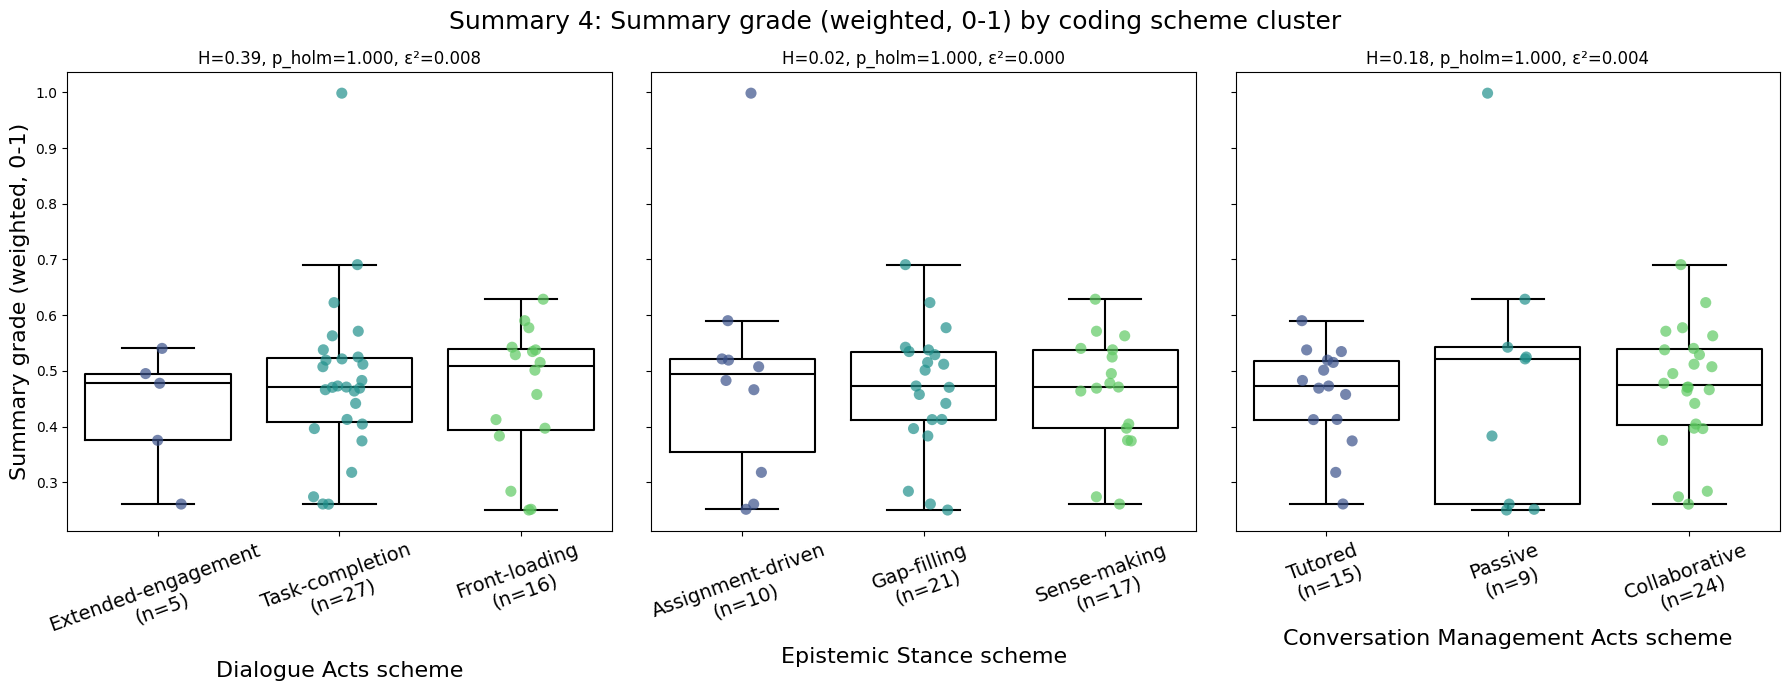

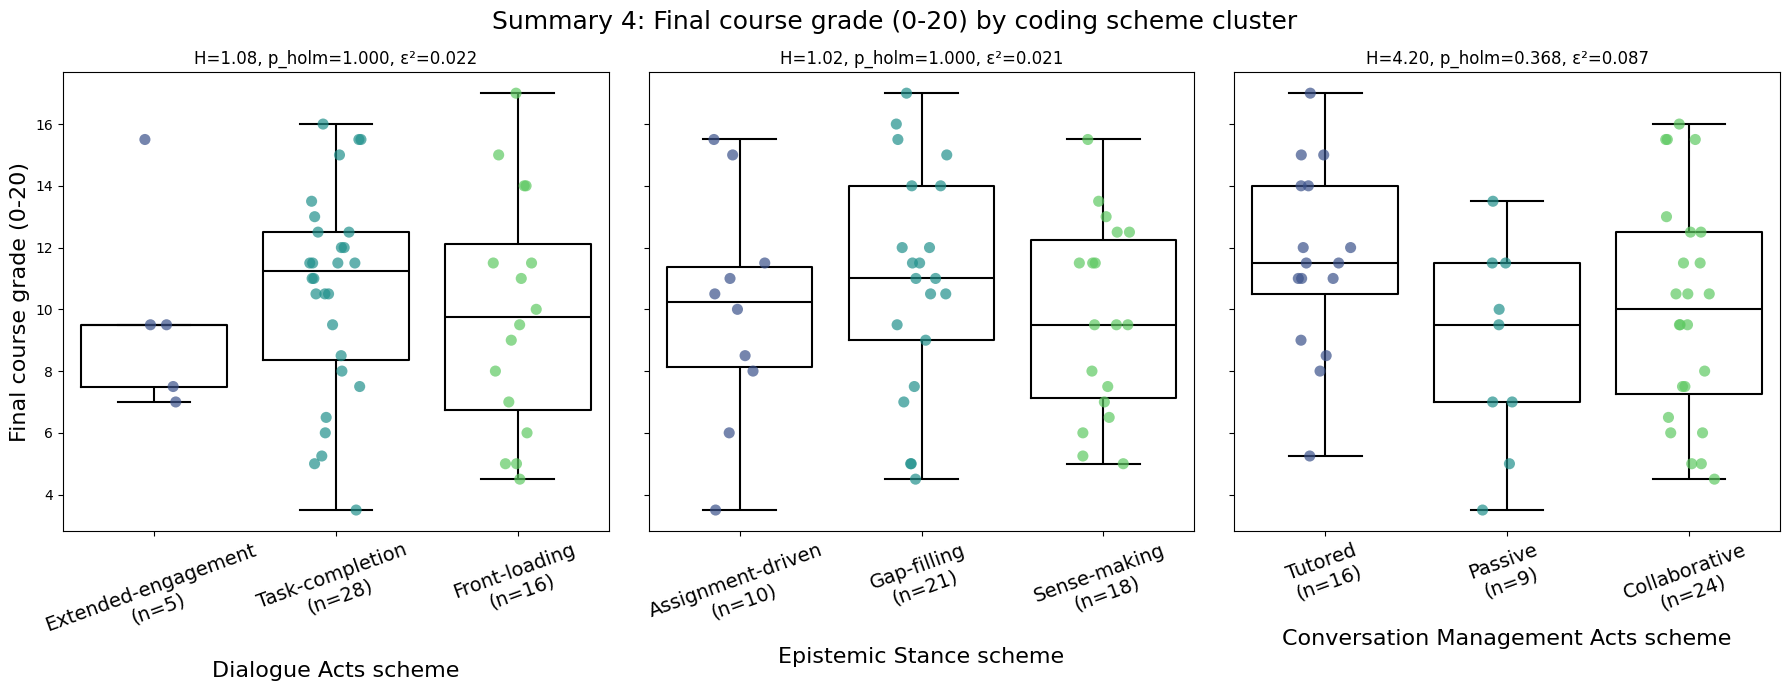

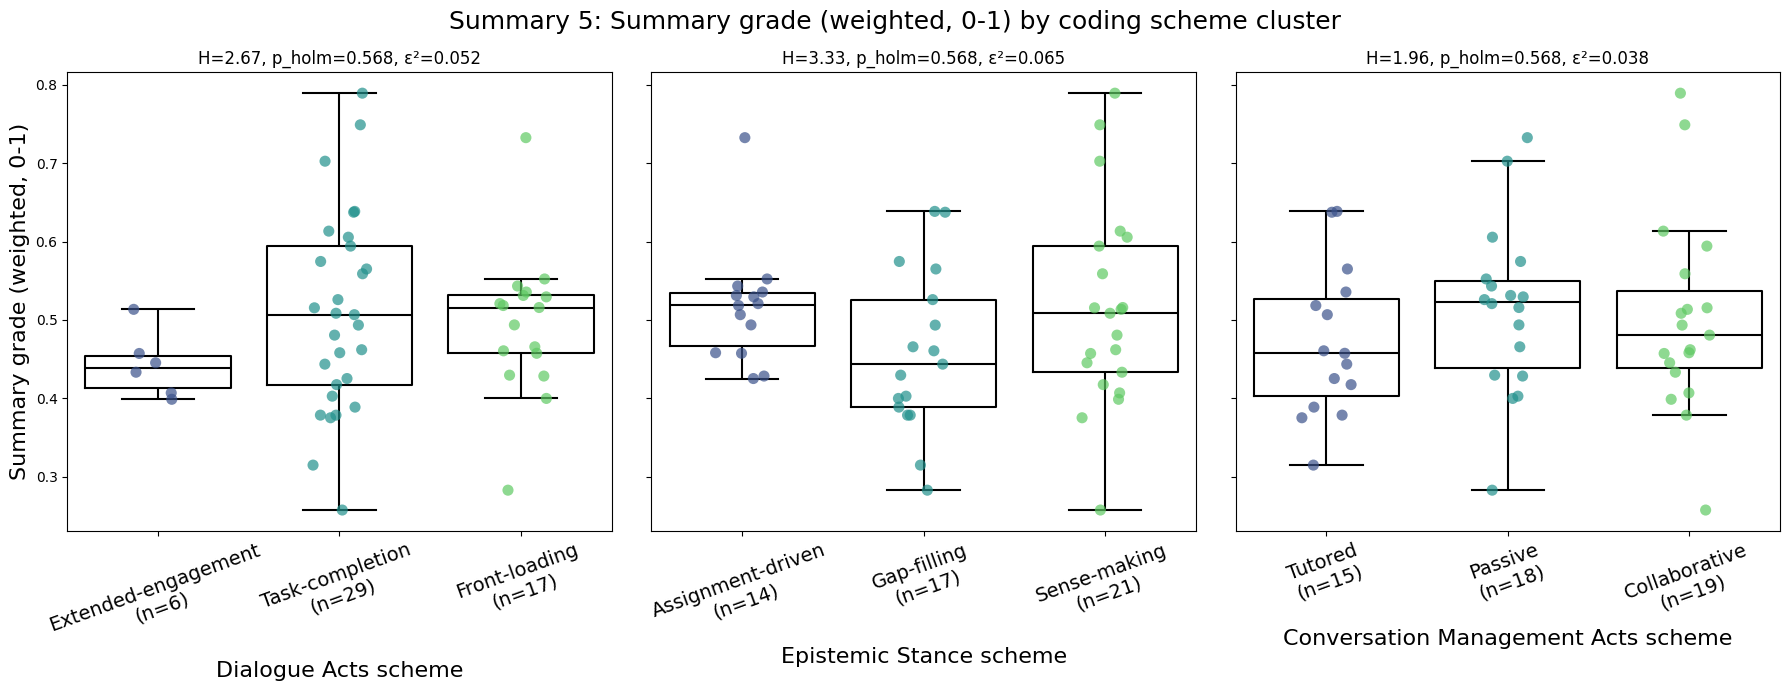

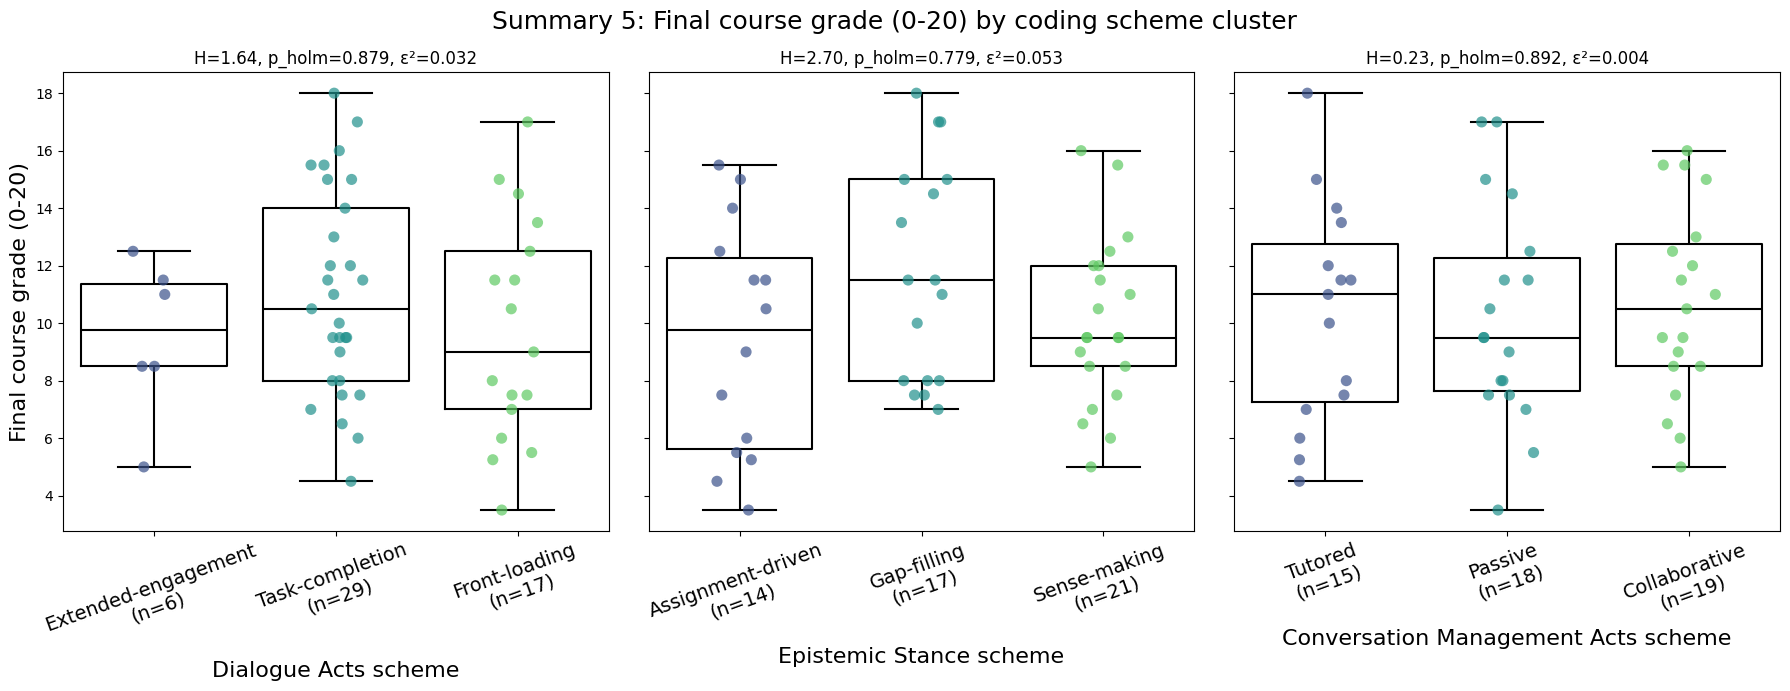

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

for activity, d in activity_dfs.items():
    for grade_col in TESTED_OUTCOMES:

        d_plot = d.dropna(subset=[grade_col])
        res = tests[(tests['activity'] == activity) & (tests['outcome'] == OUTCOMES[grade_col])]

        fig, axes = plt.subplots(1, 3, figsize=(18, 7), sharey=True)

        for ax, (col, label) in zip(axes, SCHEMES.items()):
            order = [c for c in d_plot[col].cat.categories if c in set(d_plot[col])]

            # Get counts for each cluster
            counts = d_plot[col].value_counts().reindex(order)

            # Create labels with n in parentheses
            labels_with_n = [f"{cluster}\n(n={counts[cluster]})" for cluster in order]

            sns.boxplot(data=d_plot, x=col, y=grade_col, order=order, ax=ax,
                        showfliers=False, fill=False, color='black', linewidth=1.5)

            sns.stripplot(data=d_plot, x=col, y=grade_col, order=order, ax=ax,
                          hue=col, hue_order=order, palette='viridis', alpha=0.7, jitter=0.15,
                          size=8, legend=False)

            row = res[res['col'] == col].iloc[0]

            ax.set_xticks(range(len(order)))
            ax.set_xticklabels(labels_with_n, fontsize=14, rotation=20)
            ax.set_xlabel(f'{label} scheme', fontsize=16)
            ax.set_ylabel(OUTCOMES[grade_col] if col == 'da_cluster_name' else '', fontsize=16)
            ax.set_title(f"H={row['H']:.2f}, p_holm={row['p_holm']:.3f}, ε²={row['epsilon2']:.3f}")

        plt.suptitle(f'{activity}: {OUTCOMES[grade_col]} by coding scheme cluster', fontsize=18)
        plt.tight_layout()
        plt.savefig(path_figures / f'performance_{activity.replace(" ", "_")}_{grade_col}.png',
                    dpi=200, bbox_inches='tight')
        plt.show()